In [12]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob
from contextlib import contextmanager

In [13]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")
    plt.rcParams.update({"figure.dpi": 200})

def plot(figsize=(6.4, 4.8), **kwargs):
    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols, tight=None, figsize=None):
    rows = ceildiv(n, cols)
    figsize=figsize if figsize is not None else (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten() if n != 1 else [axes]):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    if tight != False and (n != 1 or tight == True):
        plt.tight_layout()

    plot(figsize=figsize)

@contextmanager
def oneplot(tight=None, figsize=None):
    for _, ax in nplots(1, 1, tight=tight, figsize=figsize):
        yield ax

sample_prev_df=None
sample_prev_n=None
sample_ret=None

def sample(df, n=400_000):
    global sample_prev_df
    global sample_prev_n
    global sample_ret

    if sample_prev_df is df and n == sample_prev_n:
        return sample_ret

    sample_ret = None
    sample_prev_df = df
    sample_prev_n = n

    return (sample_ret := df.sample(n, random_state=217, replace=False))

In [14]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                # has NAs, but we're unlikely to use this column so
                # don't drop it
                store_and_fwd_flag="boolean",
                PULocationID="category",
                DOLocationID="category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
                duration_hours=float,
                avg_speed_mph=float,
                fare_per_hour=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean{pat}"))
    ], ignore_index=True)

In [15]:
def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """
    378798
    586920

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    # flaten column names
    df.columns = [(f"cur_{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.rename(
        columns=lambda x: x.removeprefix("cur_") if isinstance(x, str) else x,
    ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ).rename(
                columns=lambda x:
                    f"lag_{feature}-{agg}-{window}-{offset}" if x not in ["PULocationID", "pickup_hour"] else x,
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
        )

    return df

In [16]:
demand_lags = [
    ("count", "mean", "1h", ["23h", "24h", "48h"]),
    ("count", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),
]

revenue_lags = [
    ("fare_amount_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("fare_amount_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    # no linear correlations, but maybe good for correlations in a
    # latent space

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),
]

In [17]:
numerical_pipeline = sk.pipeline.Pipeline([
    ("imputer", sk.impute.SimpleImputer(strategy="mean")),
    ("scaler", sk.preprocessing.QuantileTransformer()),
])

full_pipeline = sk.compose.ColumnTransformer([
    (
        "num",
        numerical_pipeline,
        sk.compose.make_column_selector(dtype_include=np.float64),
    ),
    (
        "cat_ohe",
        sk.preprocessing.OneHotEncoder(),
        ["PULocationID", "pickup_hour_of_day"],
    ),
], remainder="drop")

In [18]:
def build_xy(rides_clean, y_col, lags, is_test=True):
    rides_feat = rides_clean.assign(
        pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
        pickup_hour_of_day = lambda x:
            x["tpep_pickup_datetime"].dt.hour +
            (x["tpep_pickup_datetime"].dt.minute / 60),
        # monday = 0
        pickup_day_of_week = lambda x:
            (x["tpep_pickup_datetime"].dt.day_of_week) +
            (x["tpep_pickup_datetime"].dt.hour / 24) +
            (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
        #ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
        ratecode_is_1 = lambda x: x["RatecodeID"].astype(str).eq("1"),
        ratecode_is_2 = lambda x: x["RatecodeID"].astype(str).eq("2"),
        ratecode_is_3 = lambda x: x["RatecodeID"].astype(str).eq("3"),
        ratecode_is_4 = lambda x: x["RatecodeID"].astype(str).eq("4"),
        ratecode_is_5 = lambda x: x["RatecodeID"].astype(str).eq("5"),
        ratecode_is_6 = lambda x: x["RatecodeID"].astype(str).eq("6"),
        ratecode_is_99 = lambda x: x["RatecodeID"].astype(str).eq("99"),
        # total amount includes extra surcharges/fees => stronger patterns tip %
        tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
    )

    rides_hour = group_zone_hour(
        rides_feat.assign(
            tip_ratio=lambda x: x["tip_amount"] / x["total_amount"],
        ),
        dict(
            passenger_count="mean",
            trip_distance=["sum", "mean"],
            # amount without tips or fees
            fare_amount=["sum", "mean"],
            # the following are somewhat fixed fees so the means
            # are losely counts of rides where the fee is charged
            # not much info intrinsically but maybe a patern?
            mta_tax="mean",
            tolls_amount="mean",
            improvement_surcharge="mean",
            congestion_surcharge="mean",
            Airport_fee="mean",
            # total amount including tips and fees
            # * in our case these are "noise" when making predictions
            # * if we really wanted to be vultures we might look at tips
            #   as an indicator of routes where we could charge more
            total_amount=["sum", "mean"],
            tip_amount="mean",
            tip_ratio="mean",
            # probably correlated with demand
            # * count used in this column arbitrarily
            duration_hours=["count", "sum", "mean"],
            avg_speed_mph="mean",
            fare_per_hour="mean",
            # ratecode_is_airport=["mean", "count"],
            ratecode_is_1="mean",
            ratecode_is_2="mean",
            ratecode_is_3="mean",
            ratecode_is_4="mean",
            ratecode_is_5="mean",
            ratecode_is_6="mean",
            ratecode_is_99="mean",
        ),
    ).assign(
        pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
    ).rename(
        columns=dict(
            cur_duration_hours_count="cur_count",
        )
    )

    X = rides_hour

    for feat, agg, window, offsets in lags:
        X = with_lags(
            X,
            feat,
            agg,
            window=window,
            offsets=offsets,
        )

    index_cols = [
        "PULocationID",
        "pickup_hour",
        "pickup_hour_of_day",
    ]

    y = X[y_col]
    X = X.drop(columns=[
        x
        for x in X.columns
        if x.startswith("cur_")
    ])

    assert all((x.startswith("lag_") or x in index_cols) for x in X.columns)

    if is_test:
        return (
            full_pipeline.transform(X),
            y,
        )
    else:
        return (
            full_pipeline.fit_transform(X, y),
            y,
        )

In [19]:
rides_train = load_clean("/train_*")
# rides_sample = load_clean("/sample_*")

/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_00.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_01.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_02.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_03.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_04.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_05.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_06.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_07.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_08.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-train-test-split-2/dataset-clean/train_09.csv
/Users/sarfaraz/Desktop/id5059-driver-scheduling-t

In [20]:
class Eval:
    def __init__(self, xy):
        self.X, self.y = xy

        [(self.train_idx, self.valid_idx)] = sk.model_selection.ShuffleSplit(
            n_splits=1,
            test_size=0.1,
            random_state=2718,
        ).split(
            self.X,
            y=self.y,
        )

    def eval(self, m):
        xv = sk.model_selection.cross_validate(
            m,
            self.X[self.train_idx].toarray(),
            self.y[self.train_idx],
            cv=5,
            scoring="neg_mean_squared_error",
            return_estimator=True,
            return_train_score=True,
            n_jobs=-1,
            verbose=10,
        )

        print(m)
        print(xv)
        print(np.min(np.sqrt(-xv["test_score"])))

        best = xv["estimator"][np.argmin(xv["test_score"])]

        return pd.DataFrame(dict(
            pred = best.predict(self.X[self.valid_idx].toarray()),
            actual = self.y[self.valid_idx],
            model = str(best),
        ))

In [21]:
def regression_scores(y_true, y_pred):
    return {
        "MAE": sk.metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(sk.metrics.mean_squared_error(y_true, y_pred)),
        "R2": sk.metrics.r2_score(y_true, y_pred),
    }

def scores_row(model_name, split_name, y_true, y_pred):
    s = regression_scores(y_true, y_pred)
    return {
        "Model": model_name,
        "Split": split_name,
        "MAE": s["MAE"],
        "RMSE": s["RMSE"],
        "R2": s["R2"],
    }

class EvalTable:
    def __init__(self, xy):
        self.X, self.y = xy

        [(self.train_idx, self.valid_idx)] = sk.model_selection.ShuffleSplit(
            n_splits=1,
            test_size=0.1,
            random_state=2718,
        ).split(
            self.X,
            y=self.y,
        )

    def fit_and_score(self, model):
        xv = sk.model_selection.cross_validate(
            model,
            self.X[self.train_idx].toarray(),
            self.y[self.train_idx],
            cv=5,
            scoring="neg_mean_squared_error",
            return_estimator=True,
            return_train_score=True,
            n_jobs=-1,
            verbose=10,
        )

        best_i = np.argmax(xv["test_score"])
        best_est = xv["estimator"][best_i]

        train_pred = best_est.predict(self.X[self.train_idx].toarray())
        valid_pred = best_est.predict(self.X[self.valid_idx].toarray())

        rows = [
            scores_row(str(best_est), "train", self.y[self.train_idx], train_pred),
            scores_row(str(best_est), "validation", self.y[self.valid_idx], valid_pred),
        ]

        return pd.DataFrame(rows), best_est


# Eval off-the-shelf models for demand

/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:41: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:51: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] END ..........., score=(train=-1173.525, test=-1164.523) total time=  10.4s
[CV] END ..........., score=(train=-1165.719, test=-1195.653) total time=  10.5s
[CV] END ..........., score=(train=-1175.912, test=-1154.816) total time=  10.5s
[CV] END ..........., score=(train=-1165.369, test=-1197.279) total time=  10.5s
[CV] END ..........., score=(train=-1177.101, test=-1150.367) total time=  10.5s


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   13.2s remaining:   19.7s
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   13.2s remaining:    8.8s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   13.3s finished


LinearRegression()
{'fit_time': array([10.45896292, 10.44666314, 10.40264797, 10.44014907, 10.38354993]), 'score_time': array([0.066365  , 0.06093168, 0.04817319, 0.05814505, 0.05431223]), 'estimator': [LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression(), LinearRegression()], 'test_score': array([-1150.3668625 , -1154.81599019, -1195.65272156, -1197.27870343,
       -1164.52278394]), 'train_score': array([-1177.10063601, -1175.91235181, -1165.7185438 , -1165.36941111,
       -1173.52516685])}
33.91705857671693


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


...

[CV] END ............., score=(train=-405.595, test=-436.898) total time= 2.0min


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END ............., score=(train=-391.815, test=-423.361) total time= 2.0min
[CV] END ............., score=(train=-396.042, test=-424.115) total time= 2.0min


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  2.0min remaining:  3.1min
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:  2.0min remaining:  1.4min
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  2.0min finished


[CV] END ............., score=(train=-388.485, test=-425.743) total time= 2.0min
[CV] END ............., score=(train=-403.783, test=-442.114) total time= 2.0min
MLPRegressor(hidden_layer_sizes=(25, 25, 10))
{'fit_time': array([119.99963212, 121.65913129, 120.68224001, 121.58593202,
       121.31564784]), 'score_time': array([0.07528782, 0.036726  , 0.07870603, 0.02991414, 0.07939887]), 'estimator': [MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10))], 'test_score': array([-423.36104526, -442.11400844, -436.89757246, -425.74326475,
       -424.11508158]), 'train_score': array([-391.81514129, -403.78294377, -405.5946969 , -388.48480636,
       -396.04229202])}
20.575739239780034


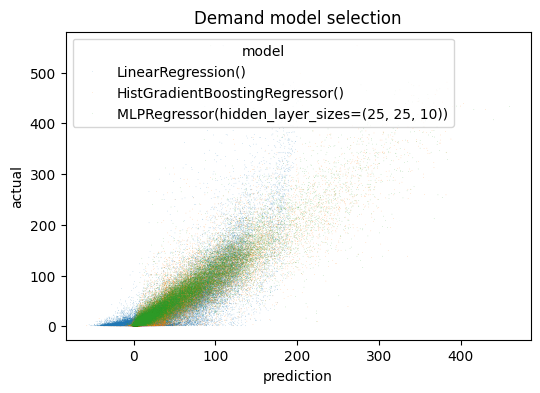

In [22]:
demand_eval = Eval(
    build_xy(rides_train, "cur_count", demand_lags, is_test=False),
)

results = pd.concat(
    (
        demand_eval.eval(m)
        for m in [
            sk.linear_model.LinearRegression(),
            sk.ensemble.HistGradientBoostingRegressor(),
            sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)),
        ]
    ),
    ignore_index=True,
)

with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        data=results,
        x="pred",
        y="actual",
        hue="model",
        s=0.2,
        alpha=0.5,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Demand model selection")


# Eval off-the-shelf models for revenue

/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:41: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:51: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] END ..............., score=(train=-37.865, test=-37.010) total time=  21.6s
[CV] END ..............., score=(train=-37.490, test=-38.501) total time=  21.7s


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   22.8s remaining:   34.2s


[CV] END ..............., score=(train=-37.888, test=-36.904) total time=  24.4s


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   25.4s remaining:   16.9s


...

[CV] END ..............., score=(train=-33.826, test=-37.153) total time= 3.1min


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  3.1min remaining:  4.6min
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:  3.1min remaining:  2.1min


[CV] END ..............., score=(train=-32.558, test=-38.132) total time= 3.1min
[CV] END ..............., score=(train=-33.739, test=-35.749) total time= 3.1min


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  3.1min finished


[CV] END ..............., score=(train=-33.349, test=-36.590) total time= 3.1min
MLPRegressor(hidden_layer_sizes=(25, 25, 10))
{'fit_time': array([184.93414283, 184.18334794, 184.35261226, 184.57525611,
       182.80727792]), 'score_time': array([0.03737712, 0.05769205, 0.08039594, 0.06430101, 0.12810302]), 'estimator': [MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10)), MLPRegressor(hidden_layer_sizes=(25, 25, 10))], 'test_score': array([-36.58955235, -37.15271852, -38.13184649, -35.74865606,
       -37.98943334]), 'train_score': array([-33.34938513, -33.82578214, -32.55791393, -33.73872362,
       -32.73977865])}
5.979017984321608


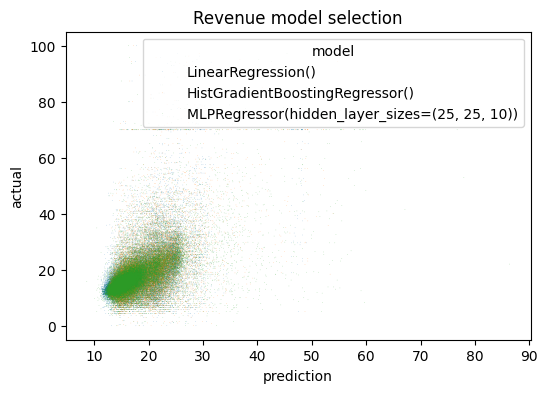

/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:41: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:51: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] END ..............., score=(train=-37.637, test=-37.916) total time=  15.6s
[CV] END ..............., score=(train=-37.889, test=-36.904) total time=  15.6s


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   16.8s remaining:   25.2s


[CV] END ..............., score=(train=-37.866, test=-37.010) total time=  16.6s


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   17.5s remaining:   11.6s


...

[CV] END ..............., score=(train=-33.238, test=-36.295) total time= 2.2min
[CV] END ..............., score=(train=-32.220, test=-38.371) total time= 2.2min


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  2.2min remaining:  3.3min
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:  2.2min remaining:  1.5min


[CV] END ..............., score=(train=-34.470, test=-35.247) total time= 2.2min
[CV] END ..............., score=(train=-32.933, test=-38.267) total time= 2.2min


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  2.2min finished


[CV] END ..............., score=(train=-33.384, test=-38.345) total time= 2.2min
                                           Model       Split       MAE  \
0                             LinearRegression()       train  3.577234   
1                             LinearRegression()  validation  3.614790   
2                HistGradientBoostingRegressor()       train  3.464150   
3                HistGradientBoostingRegressor()  validation  3.534204   
4  MLPRegressor(hidden_layer_sizes=(25, 25, 10))       train  3.421289   
5  MLPRegressor(hidden_layer_sizes=(25, 25, 10))  validation  3.509695   

       RMSE        R2  
0  6.139353  0.290537  
1  6.251153  0.296594  
2  5.951600  0.333267  
3  6.175248  0.313573  
4  5.884352  0.348249  
5  6.120113  0.325775  
                                           Model  MAE_train  MAE_validation  \
0                HistGradientBoostingRegressor()   3.464150        3.534204   
1                             LinearRegression()   3.577234        3.61479

In [23]:
# revenue_eval = Eval(
#     build_xy(rides_train, "cur_fare_amount_mean", revenue_lags, is_test=False),
# )

# results = pd.concat(
#     (
#         revenue_eval.eval(m)
#         for m in [
#             sk.linear_model.LinearRegression(),
#             sk.ensemble.HistGradientBoostingRegressor(),
#             sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)),
#         ]
#     ),
#     ignore_index=True,
# )

# with oneplot() as ax:
#     sns.scatterplot(
#         ax=ax,
#         data=results,
#         x="pred",
#         y="actual",
#         hue="model",
#         s=0.2,
#         alpha=0.5,
#         linewidth=0,
#     ),
#     ax.set_xlabel("prediction")
#     ax.set_ylabel("actual")
#     ax.set_title("Revenue model selection")
revenue_eval = Eval(
    build_xy(rides_train, "cur_fare_amount_mean", revenue_lags, is_test=False),
)

results = pd.concat(
    (
        revenue_eval.eval(m)
        for m in [
            sk.linear_model.LinearRegression(),
            sk.ensemble.HistGradientBoostingRegressor(),
            sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)),
        ]
    ),
    ignore_index=True,
)

with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        data=results,
        x="pred",
        y="actual",
        hue="model",
        s=0.2,
        alpha=0.5,
        linewidth=0,
    )
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Revenue model selection")

revenue_eval_table = EvalTable(
    build_xy(rides_train, "cur_fare_amount_mean", revenue_lags, is_test=False),
)

revenue_models = [
    sk.linear_model.LinearRegression(),
    sk.ensemble.HistGradientBoostingRegressor(),
    sk.neural_network.MLPRegressor(hidden_layer_sizes=(25, 25, 10)),
]

revenue_perf_tables = []
revenue_best_estimators = []

for m in revenue_models:
    perf_df, best_est = revenue_eval_table.fit_and_score(m)
    revenue_perf_tables.append(perf_df)
    revenue_best_estimators.append(best_est)

revenue_performance = pd.concat(revenue_perf_tables, ignore_index=True)

print(revenue_performance)

revenue_summary = revenue_performance.pivot_table(
    index="Model",
    columns="Split",
    values=["MAE", "RMSE", "R2"],
)

revenue_summary.columns = [
    f"{metric}_{split}" for metric, split in revenue_summary.columns
]
revenue_summary = revenue_summary.reset_index()

print(revenue_summary)

## To get a proper tuning table

In [24]:
class TuneMLP:
    def __init__(self, xy):
        self.X, self.y = xy

        [(self.train_idx, self.valid_idx)] = sk.model_selection.ShuffleSplit(
            n_splits=1,
            test_size=0.1,
            random_state=2718,
        ).split(
            self.X,
            y=self.y,
        )

    def tune(self, param_grid):
        results = []

        for params in sk.model_selection.ParameterGrid(param_grid):
            m = sk.pipeline.Pipeline([
                ("prep", full_pipeline),
                ("mlp", sk.neural_network.MLPRegressor(
                    **params,
                    random_state=2718,
                    max_iter=400,
                    early_stopping=True,
                    n_iter_no_change=10,
                )),
            ])

            xv = sk.model_selection.cross_validate(
                m,
                self.X.iloc[self.train_idx],
                self.y.iloc[self.train_idx],
                cv=5,
                scoring="neg_mean_squared_error",
                return_estimator=True,
                return_train_score=True,
                n_jobs=-1,
                verbose=10,
            )

            cv_rmse = np.sqrt(-xv["test_score"])
            train_rmse = np.sqrt(-xv["train_score"])

            best_i = np.argmax(xv["test_score"])
            best_est = xv["estimator"][best_i]

            valid_pred = best_est.predict(self.X.iloc[self.valid_idx])
            valid_rmse = np.sqrt(
                sk.metrics.mean_squared_error(
                    self.y.iloc[self.valid_idx],
                    valid_pred,
                )
            )

            results.append({
                **params,
                "cv_rmse_mean": cv_rmse.mean(),
                "cv_rmse_std": cv_rmse.std(),
                "cv_rmse_best_fold": cv_rmse.min(),
                "train_rmse_mean": train_rmse.mean(),
                "valid_rmse": valid_rmse,
                "best_estimator": best_est,
            })

        return pd.DataFrame(results).sort_values(
            ["valid_rmse", "cv_rmse_mean"],
            ascending=True,
        ).reset_index(drop=True)

# Getting untransformed X/y before pipeline

In [ ]:
# def build_xy_raw(rides_clean, y_col, lags):
#     rides_feat = rides_clean.assign(
#         pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
#         pickup_hour_of_day = lambda x:
#             x["tpep_pickup_datetime"].dt.hour +
#             (x["tpep_pickup_datetime"].dt.minute / 60),
#         pickup_day_of_week = lambda x:
#             (x["tpep_pickup_datetime"].dt.day_of_week) +
#             (x["tpep_pickup_datetime"].dt.hour / 24) +
#             (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
#         ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
#         tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
#     )

#     rides_hour = group_zone_hour(
#         rides_feat.assign(
#             tip_ratio=lambda x: x["tip_amount"] / x["total_amount"],
#         ),
#         dict(
#             passenger_count="mean",
#             trip_distance=["sum", "mean"],
#             fare_amount=["sum", "mean"],
#             mta_tax="mean",
#             tolls_amount="mean",
#             improvement_surcharge="mean",
#             congestion_surcharge="mean",
#             Airport_fee="mean",
#             total_amount=["sum", "mean"],
#             tip_amount="mean",
#             tip_ratio="mean",
#             duration_hours=["count", "sum", "mean"],
#             avg_speed_mph="mean",
#             fare_per_hour="mean",
#             ratecode_is_airport=["mean", "count"],
#         ),
#     )

#     for args in lags:
#         rides_hour = with_lags(rides_hour, *args)

#     rides_hour = rides_hour.dropna()

#     y = rides_hour[y_col]
#     X = rides_hour.drop(
#         columns=[c for c in rides_hour.columns if isinstance(c, str) and c.startswith("cur_")]
#     )

#     return X, y
# Getting untransformed X/y before pipeline
def build_xy_raw(rides_clean, y_col, lags):
    rides_feat = rides_clean.assign(
        pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
        pickup_hour_of_day = lambda x:
            x["tpep_pickup_datetime"].dt.hour +
            (x["tpep_pickup_datetime"].dt.minute / 60),
        pickup_day_of_week = lambda x:
            (x["tpep_pickup_datetime"].dt.day_of_week) +
            (x["tpep_pickup_datetime"].dt.hour / 24) +
            (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
        # ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
        ratecode_is_1=lambda x: x["RatecodeID"].astype(str).eq("1"),
        ratecode_is_2=lambda x: x["RatecodeID"].astype(str).eq("2"),
        ratecode_is_3=lambda x: x["RatecodeID"].astype(str).eq("3"),
        ratecode_is_4=lambda x: x["RatecodeID"].astype(str).eq("4"),
        ratecode_is_5=lambda x: x["RatecodeID"].astype(str).eq("5"),
        ratecode_is_6=lambda x: x["RatecodeID"].astype(str).eq("6"),
        ratecode_is_99=lambda x: x["RatecodeID"].astype(str).eq("99"),
        tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
    )

    rides_hour = group_zone_hour(
        rides_feat.assign(
            tip_ratio=lambda x: x["tip_amount"] / x["total_amount"],
        ),
        dict(
            passenger_count="mean",
            trip_distance=["sum", "mean"],
            fare_amount=["sum", "mean"],
            mta_tax="mean",
            tolls_amount="mean",
            improvement_surcharge="mean",
            congestion_surcharge="mean",
            Airport_fee="mean",
            total_amount=["sum", "mean"],
            tip_amount="mean",
            tip_ratio="mean",
            duration_hours=["count", "sum", "mean"],
            avg_speed_mph="mean",
            fare_per_hour="mean",
            #ratecode_is_airport=["mean", "count"],
            ratecode_is_1="mean",
            ratecode_is_2="mean",
            ratecode_is_3="mean",
            ratecode_is_4="mean",
            ratecode_is_5="mean",
            ratecode_is_6="mean",
            ratecode_is_99="mean",
        ),
    ).assign(
        # Re-assigning this because group_zone_hour drops non-aggregated/grouped columns
        pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
    ).rename(
        columns=dict(
            cur_duration_hours_count="cur_count", 
        )
    )

    for args in lags:
        rides_hour = with_lags(rides_hour, *args)

    rides_hour = rides_hour.dropna()

    y = rides_hour[y_col]
    X = rides_hour.drop(
        columns=[c for c in rides_hour.columns if isinstance(c, str) and c.startswith("cur_")]
    )

    return X, y

# Tuning the demand neural network

In [26]:
demand_tuner = TuneMLP(
    build_xy_raw(rides_train, "cur_count", demand_lags)
)

demand_param_grid = {
    "hidden_layer_sizes": [
        (25, 25, 10),
        (50, 25),
        (50, 50),
        (100,),
        (100, 50),
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01],
}

demand_mlp_results = demand_tuner.tune(demand_param_grid)

demand_mlp_results[
    [
        "hidden_layer_sizes",
        "activation",
        "alpha",
        "learning_rate_init",
        "cv_rmse_mean",
        "cv_rmse_std",
        "cv_rmse_best_fold",
        "valid_rmse",
    ]
].head(10)

/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:41: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:51: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] END ............., score=(train=-438.259, test=-484.999) total time=  53.8s
[CV] END ............., score=(train=-432.676, test=-448.072) total time= 1.0min


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:  1.1min remaining:  1.6min


[CV] END ............., score=(train=-434.128, test=-455.110) total time= 1.1min


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:  1.1min remaining:   43.4s


...

[CV] END ............., score=(train=-420.394, test=-451.007) total time= 1.1min


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:  1.2min remaining:   46.4s


[CV] END ............., score=(train=-428.331, test=-463.024) total time= 1.1min
[CV] END ............., score=(train=-403.063, test=-465.441) total time= 1.2min


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  1.2min finished


,hidden_layer_sizes,activation,alpha,learning_rate_init,cv_rmse_mean,cv_rmse_std,cv_rmse_best_fold,valid_rmse
0,"(100, 50)",tanh,0.0100,0.001,19.854428,0.321937,19.569600,19.440099
1,"(50, 50)",tanh,0.0100,0.001,20.068732,0.240425,19.613346,19.464912
2,"(100, 50)",tanh,0.0001,0.001,19.873464,0.398371,19.531806,19.539054
3,"(50, 25)",tanh,0.0100,0.001,20.087513,0.340599,19.708057,19.553029
4,"(100, 50)",relu,0.0010,0.001,20.229093,0.325022,19.778746,19.564492
5,"(50, 50)",tanh,0.0010,0.001,20.270357,0.191982,20.045940,19.657034
6,"(100, 50)",relu,0.0010,0.010,20.239428,0.347168,19.815920,19.668483
7,"(50, 50)",tanh,0.0001,0.001,20.061846,0.187227,19.796113,19.675261
8,"(25, 25, 10)",tanh,0.0100,0.001,20.263045,0.259035,20.006904,19.688496
9,"(100, 50)",tanh,0.0010,0.001,20.067885,0.245342,19.702294,19.705950


# Tuning the revenue neural network 

In [27]:
revenue_tuner = TuneMLP(
    build_xy_raw(rides_train, "cur_fare_amount_mean", revenue_lags)
)

revenue_param_grid = {
    "hidden_layer_sizes": [
        (25, 25, 10),
        (50, 25),
        (50, 50),
        (100,),
        (100, 50),
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01],
}

revenue_mlp_results = revenue_tuner.tune(revenue_param_grid)

revenue_mlp_results[
    [
        "hidden_layer_sizes",
        "activation",
        "alpha",
        "learning_rate_init",
        "cv_rmse_mean",
        "cv_rmse_std",
        "cv_rmse_best_fold",
        "valid_rmse",
    ]
].head(10)

/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:41: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
/var/folders/bx/88_yjnt54jb21f88nkt4x5_80000gn/T/ipykernel_50626/1378680063.py:51: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] START .....................................................................
[CV] END ..............., score=(train=-19.120, test=-20.829) total time=  26.6s
[CV] END ..............., score=(train=-19.198, test=-19.991) total time=  27.6s


[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   32.2s remaining:   48.4s


[CV] END ..............., score=(train=-19.682, test=-18.486) total time=  28.4s


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   33.2s remaining:   22.1s


...

[CV] END ..............., score=(train=-19.903, test=-18.628) total time=  24.7s


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   26.4s remaining:   17.6s


[CV] END ..............., score=(train=-19.707, test=-19.620) total time=  26.3s
[CV] END ..............., score=(train=-19.255, test=-21.129) total time=  27.6s


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   28.7s finished


,hidden_layer_sizes,activation,alpha,learning_rate_init,cv_rmse_mean,cv_rmse_std,cv_rmse_best_fold,valid_rmse
0,"(100,)",tanh,0.0100,0.001,4.425417,0.096120,4.264267,4.412169
1,"(100,)",tanh,0.0010,0.001,4.425065,0.096030,4.264357,4.412362
2,"(100,)",tanh,0.0001,0.001,4.425083,0.095960,4.264426,4.412433
3,"(50, 25)",tanh,0.0100,0.001,4.437063,0.098167,4.273526,4.413972
4,"(50, 25)",tanh,0.0001,0.001,4.434463,0.096028,4.274878,4.414717
5,"(50, 25)",tanh,0.0010,0.001,4.434724,0.095709,4.275532,4.415619
6,"(100,)",tanh,0.0010,0.010,4.439867,0.094067,4.283432,4.416974
7,"(100,)",tanh,0.0100,0.010,4.440255,0.094775,4.282964,4.418071
8,"(100, 50)",tanh,0.0010,0.001,4.434852,0.098625,4.272121,4.418178
9,"(100,)",tanh,0.0001,0.010,4.442702,0.095100,4.284833,4.418352


## BEst tuned demand model

In [28]:
best_demand_mlp = demand_mlp_results.loc[0, "best_estimator"]
best_demand_mlp

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat_ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

## Best tuned revenue model

In [29]:
best_revenue_mlp = revenue_mlp_results.loc[0, "best_estimator"]
best_revenue_mlp

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat_ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains